In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"C:\Users\praso\Downloads\Saudi Employee Attrition Dataset\02_Cleaned_Data\employee_attrition_clean.csv"
)

print("Shape:", df.shape)

Shape: (1191, 44)


In [2]:
# Create a fresh Series for the chart
attrition_counts = df["Attrition"].value_counts()

print(attrition_counts)
print(type(attrition_counts))

Attrition
No     676
Yes    515
Name: count, dtype: int64
<class 'pandas.core.series.Series'>


In [3]:
total_employees = len(df)
attrition_count = df["AttritionFlag"].sum()

attrition_rate = (attrition_count / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees with Attrition:", attrition_count)
print(f"Attrition Rate: {attrition_rate:.2f}%")

Total Employees: 1191
Employees with Attrition: 515
Attrition Rate: 43.24%


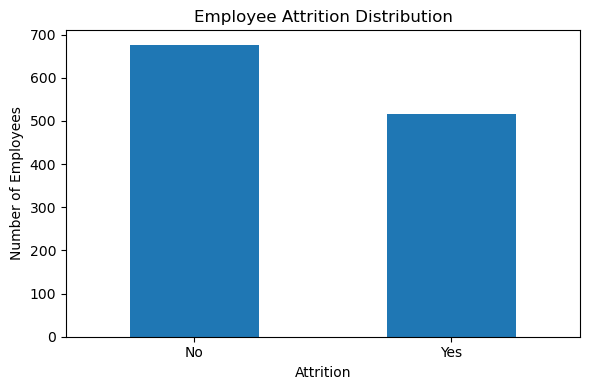

In [4]:
attrition_counts.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
gender_attrition = (
    df.groupby("Gender")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

gender_attrition["AttritionRate"] = gender_attrition["mean"] * 100

gender_attrition

,Gender,count,sum,mean,AttritionRate
0,Female,678,266,0.39233,39.233038
1,Male,513,249,0.48538,48.538012


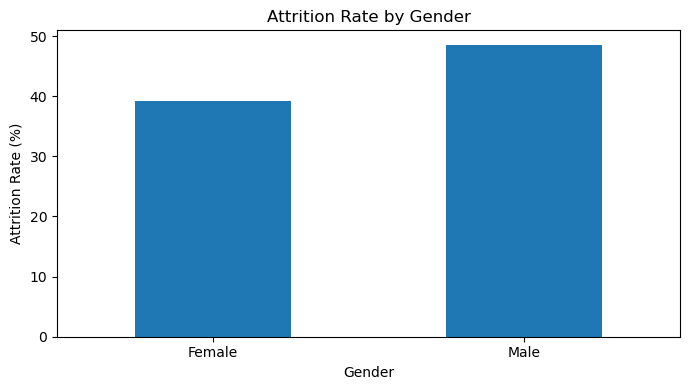

In [6]:
gender_attrition.plot(
    x="Gender",
    y="AttritionRate",
    kind="bar",
    figsize=(7, 4),
    legend=False
)

plt.title("Attrition Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
age_order = [
    "21 to 30",
    "31 to 40",
    "41 to 50",
    "51 to 60"
]

age_attrition = (
    df.groupby("Age")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

age_attrition["AttritionRate"] = age_attrition["mean"] * 100

age_attrition["Age"] = pd.Categorical(
    age_attrition["Age"],
    categories=age_order,
    ordered=True
)

age_attrition = age_attrition.sort_values("Age")

age_attrition

,Age,count,sum,mean,AttritionRate
0,21 to 30,592,269,0.454392,45.439189
1,31 to 40,459,198,0.431373,43.137255
2,41 to 50,127,42,0.330709,33.070866
3,51 to 60,13,6,0.461538,46.153846


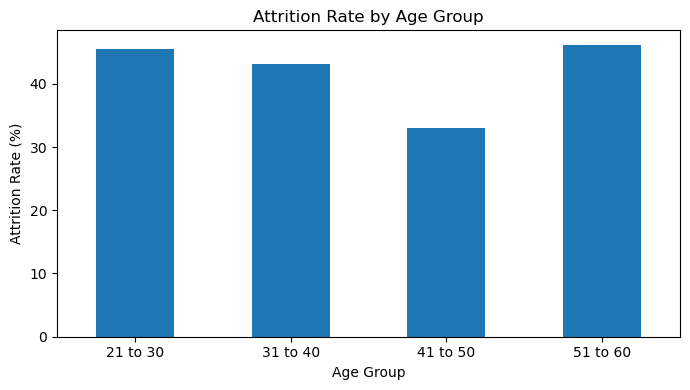

In [8]:
age_attrition.plot(
    x="Age",
    y="AttritionRate",
    kind="bar",
    figsize=(7, 4),
    legend=False
)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
marital_attrition = (
    df.groupby("Maritalstatus")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

marital_attrition["AttritionRate"] = marital_attrition["mean"] * 100

marital_attrition = marital_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

marital_attrition

,Maritalstatus,count,sum,mean,AttritionRate
0,Divorced,25,12,0.480000,48.000000
2,Single,480,218,0.454167,45.416667
1,Married,686,285,0.415452,41.545190


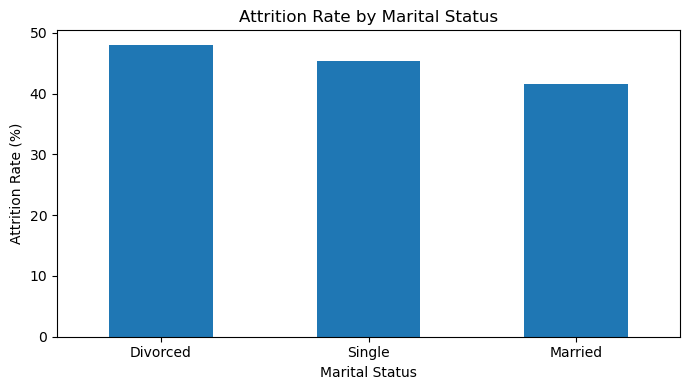

In [10]:
marital_attrition.plot(
    x="Maritalstatus",
    y="AttritionRate",
    kind="bar",
    figsize=(7, 4),
    legend=False
)

plt.title("Attrition Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
degree_attrition = (
    df.groupby("Academic_degree")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

degree_attrition["AttritionRate"] = degree_attrition["mean"] * 100

degree_attrition = degree_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

degree_attrition

,Academic_degree,count,sum,mean,AttritionRate
2,Master's,149,67,0.449664,44.966443
0,Bachelor's,764,332,0.434555,43.455497
1,Diploma or secondary,247,107,0.433198,43.319838
3,Ph.D,31,9,0.290323,29.032258


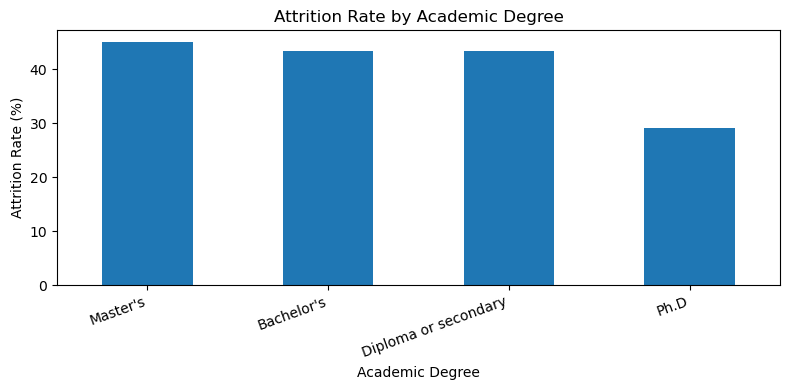

In [12]:
degree_attrition.plot(
    x="Academic_degree",
    y="AttritionRate",
    kind="bar",
    figsize=(8, 4),
    legend=False
)

plt.title("Attrition Rate by Academic Degree")
plt.xlabel("Academic Degree")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [13]:
experience_attrition = (
    df.groupby("Years_Experience")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

experience_attrition["AttritionRate"] = (
    experience_attrition["mean"] * 100
)

experience_order = [
    "Less than 5 years",
    "From 5 to 10 years",
    "From 11 to 15 years",
    "From 16 to 20 years",
    "From 21 to 25 years",
    "From 26 to 30 years",
    "From 31 to 35 years"
]

experience_attrition["Years_Experience"] = pd.Categorical(
    experience_attrition["Years_Experience"],
    categories=experience_order,
    ordered=True
)

experience_attrition = experience_attrition.sort_values(
    "Years_Experience"
)

experience_attrition

,Years_Experience,count,sum,mean,AttritionRate
6,Less than 5 years,498,164,0.329317,32.931727
5,From 5 to 10 years,500,266,0.532000,53.200000
0,From 11 to 15 years,114,54,0.473684,47.368421
1,From 16 to 20 years,46,20,0.434783,43.478261
2,From 21 to 25 years,20,7,0.350000,35.000000
3,From 26 to 30 years,9,4,0.444444,44.444444
4,From 31 to 35 years,4,0,0.000000,0.000000


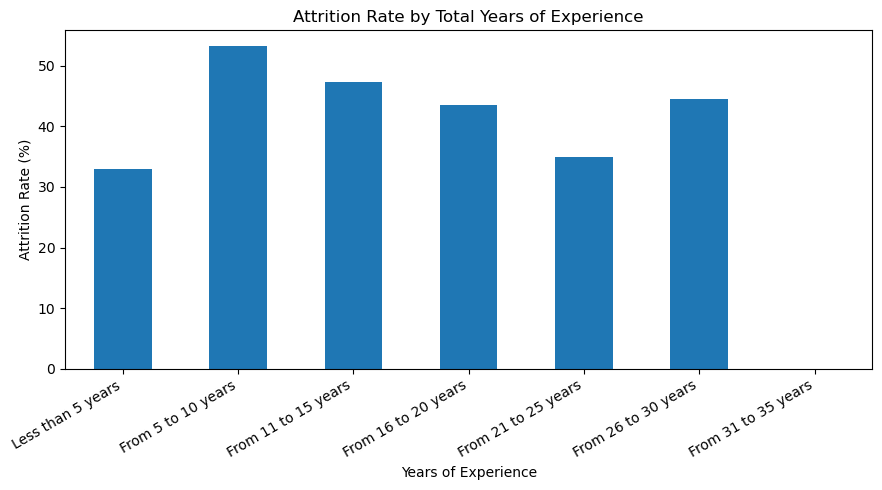

In [14]:
experience_attrition.plot(
    x="Years_Experience",
    y="AttritionRate",
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Attrition Rate by Total Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [15]:
org_experience_attrition = (
    df.groupby("Years_experience_lastorganization")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

org_experience_attrition["AttritionRate"] = (
    org_experience_attrition["mean"] * 100
)

org_experience_order = [
    "Less than 5 years",
    "From 5 to 10 years",
    "From 11 to 15 years",
    "From 16 to 20 years",
    "From 21 to 25 years",
    "From 26 to 30 years",
    "From 31 to 35 years"
]

org_experience_attrition["Years_experience_lastorganization"] = pd.Categorical(
    org_experience_attrition["Years_experience_lastorganization"],
    categories=org_experience_order,
    ordered=True
)

org_experience_attrition = org_experience_attrition.sort_values(
    "Years_experience_lastorganization"
)

org_experience_attrition

,Years_experience_lastorganization,count,sum,mean,AttritionRate
6,Less than 5 years,716,382,0.533520,53.351955
5,From 5 to 10 years,352,118,0.335227,33.522727
0,From 11 to 15 years,75,15,0.200000,20.000000
1,From 16 to 20 years,26,0,0.000000,0.000000
2,From 21 to 25 years,13,0,0.000000,0.000000
3,From 26 to 30 years,5,0,0.000000,0.000000
4,From 31 to 35 years,4,0,0.000000,0.000000


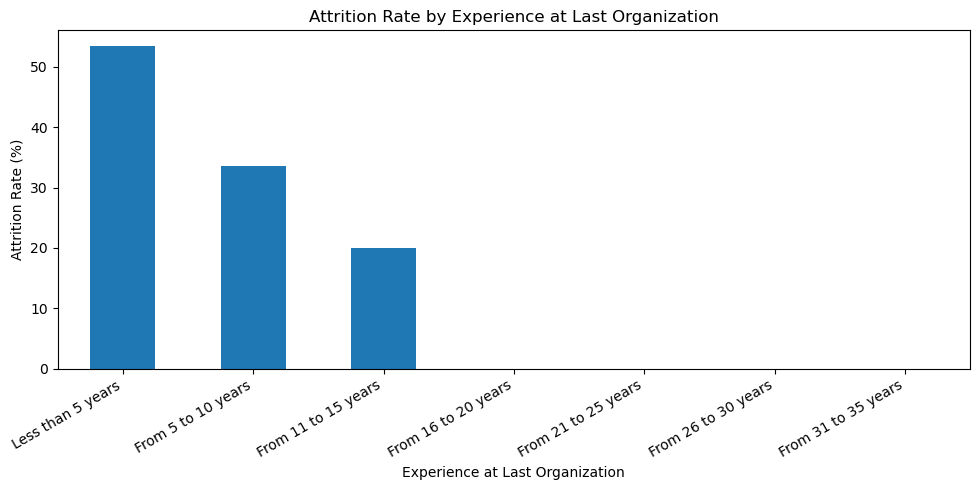

In [16]:
org_experience_attrition.plot(
    x="Years_experience_lastorganization",
    y="AttritionRate",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Attrition Rate by Experience at Last Organization")
plt.xlabel("Experience at Last Organization")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [17]:
sector_attrition = (
    df.groupby("Sector")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

sector_attrition["AttritionRate"] = (
    sector_attrition["mean"] * 100
)

sector_attrition = sector_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

sector_attrition

,Sector,count,sum,mean,AttritionRate
0,Communications and IT sector,64,48,0.750000,75.000000
3,Energy sector,47,34,0.723404,72.340426
4,Engineering consulting companies,14,10,0.714286,71.428571
10,Media sector,13,9,0.692308,69.230769
1,Economic sector,48,30,0.625000,62.500000
8,Industry sector,27,15,0.555556,55.555556
5,"Environment, Water, and Agriculture sector",27,14,0.518519,51.851852
7,Food production sector,114,59,0.517544,51.754386
12,Restaurant sector,2,1,0.500000,50.000000
13,Tourism sector,26,13,0.500000,50.000000


In [18]:
print("Number of unique sectors:", df["Sector"].nunique())
print(df["Sector"].unique())

Number of unique sectors: 15
['Medical sector' 'Education sector' 'Communications and IT sector'
 'Tourism sector' 'Financial sector' 'Economic sector' 'Transport sector'
 'Food production sector' 'Industry sector' 'Media sector'
 'Engineering consulting companies'
 'Environment, Water, and Agriculture sector' 'Law firm' 'Energy sector'
 'Restaurant sector']


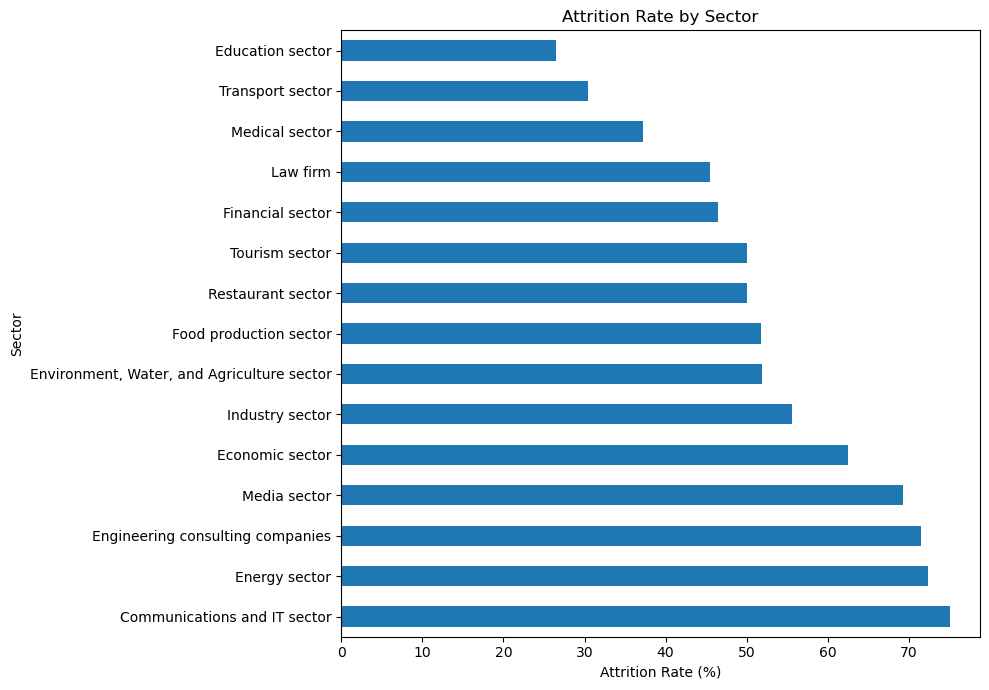

In [19]:
sector_attrition.plot(
    x="Sector",
    y="AttritionRate",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("Attrition Rate by Sector")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()

In [20]:
department_attrition = (
    df.groupby("Department")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

department_attrition["AttritionRate"] = department_attrition["mean"] * 100

department_attrition = department_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

department_attrition

,Department,count,sum,mean,AttritionRate
4,Engineering,1,1,1.000000,100.000000
16,Studies and design,4,4,1.000000,100.000000
9,Medical service,1,1,1.000000,100.000000
20,Treasury,6,5,0.833333,83.333333
8,Marketing,15,11,0.733333,73.333333
14,Safety & Security,27,18,0.666667,66.666667
5,HR,45,28,0.622222,62.222222
0,Accounting,64,39,0.609375,60.937500
11,Processes,99,56,0.565657,56.565657
13,Relations,34,19,0.558824,55.882353


In [21]:
job_title_attrition = (
    df.groupby("JobTitle")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_title_attrition["AttritionRate"] = (
    job_title_attrition["mean"] * 100
)

job_title_attrition = job_title_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

job_title_attrition

,JobTitle,count,sum,mean,AttritionRate
6,after sales service manager,1,1,1.000000,100.000000
15,cybersecurity director,1,1,1.000000,100.000000
24,graphic designer,3,3,1.000000,100.000000
26,hiring specialist,17,17,1.000000,100.000000
44,quality controller,3,3,1.000000,100.000000
...,...,...,...,...,...
58,teacher,165,32,0.193939,19.393939
45,quality specialist,6,1,0.166667,16.666667
17,dentist,11,1,0.090909,9.090909
9,business partners,1,0,0.000000,0.000000


In [22]:
job_title_filtered = job_title_attrition[
    job_title_attrition["count"] >= 5
].copy()

job_title_filtered = job_title_filtered.sort_values(
    "AttritionRate",
    ascending=False
)

job_title_filtered

,JobTitle,count,sum,mean,AttritionRate
26,hiring specialist,17,17,1.000000,100.000000
20,electrical engineer,12,10,0.833333,83.333333
33,marketing specialist,18,14,0.777778,77.777778
54,secretariat,9,7,0.777778,77.777778
49,relationships specialist,20,14,0.700000,70.000000
51,sales executive,32,22,0.687500,68.750000
23,financial manager,12,8,0.666667,66.666667
11,civil engineer,9,6,0.666667,66.666667
48,relations manager,9,6,0.666667,66.666667
4,admin accountant,9,6,0.666667,66.666667


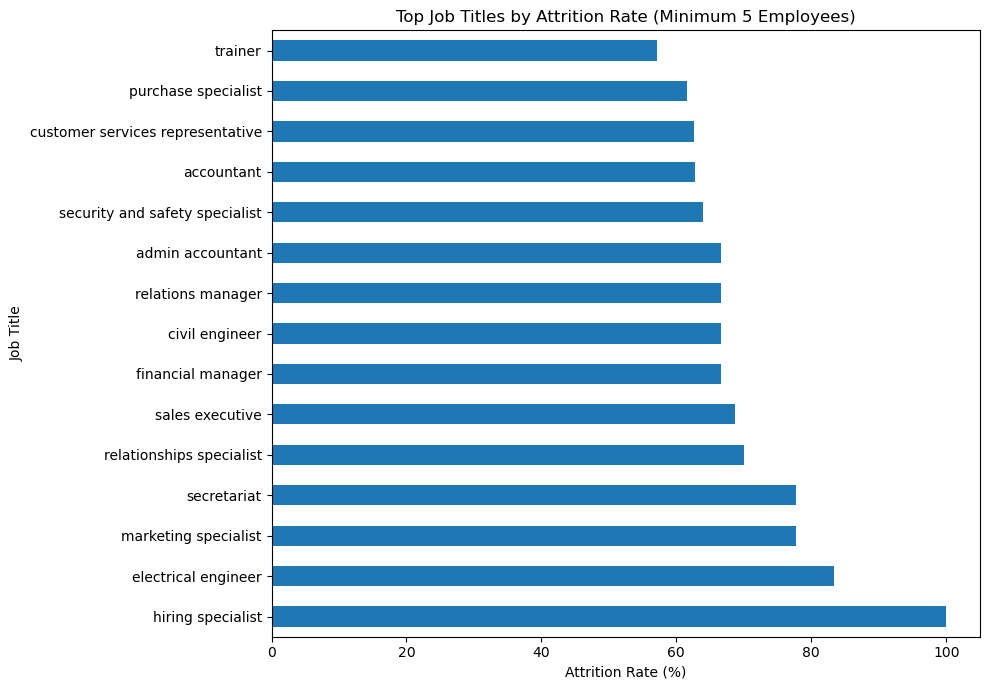

In [23]:
top_job_titles = job_title_filtered.head(15)

top_job_titles.plot(
    x="JobTitle",
    y="AttritionRate",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("Top Job Titles by Attrition Rate (Minimum 5 Employees)")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

In [24]:
print(
    sorted(
        [x for x in df["JobTitle"].dropna().unique()
         if "it specialist" in x.lower()]
    )
)

['IT Specialist']


In [25]:
print(
    sorted(
        [x for x in df["JobTitle"].dropna().unique()
         if "salesman" in x.lower()]
    )
)

['Salesman']


In [26]:
df = pd.read_csv(
    r"C:\Users\praso\Downloads\Saudi Employee Attrition Dataset\02_Cleaned_Data\employee_attrition_clean.csv"
)

print("Shape:", df.shape)

Shape: (1191, 44)


In [27]:
print(
    sorted(
        [x for x in df["JobTitle"].dropna().unique()
         if "it specialist" in x.lower()]
    )
)

print(
    sorted(
        [x for x in df["JobTitle"].dropna().unique()
         if "salesman" in x.lower()]
    )
)

['IT Specialist']
['Salesman']


In [28]:
job_title_attrition = (
    df.groupby("JobTitle")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_title_attrition["AttritionRate"] = (
    job_title_attrition["mean"] * 100
)

job_title_filtered = job_title_attrition[
    job_title_attrition["count"] >= 5
].copy()

job_title_filtered = job_title_filtered.sort_values(
    "AttritionRate",
    ascending=False
)

job_title_filtered

,JobTitle,count,sum,mean,AttritionRate
26,hiring specialist,17,17,1.000000,100.000000
20,electrical engineer,12,10,0.833333,83.333333
54,secretariat,9,7,0.777778,77.777778
33,marketing specialist,18,14,0.777778,77.777778
49,relationships specialist,20,14,0.700000,70.000000
51,sales executive,32,22,0.687500,68.750000
23,financial manager,12,8,0.666667,66.666667
48,relations manager,9,6,0.666667,66.666667
11,civil engineer,9,6,0.666667,66.666667
4,admin accountant,9,6,0.666667,66.666667


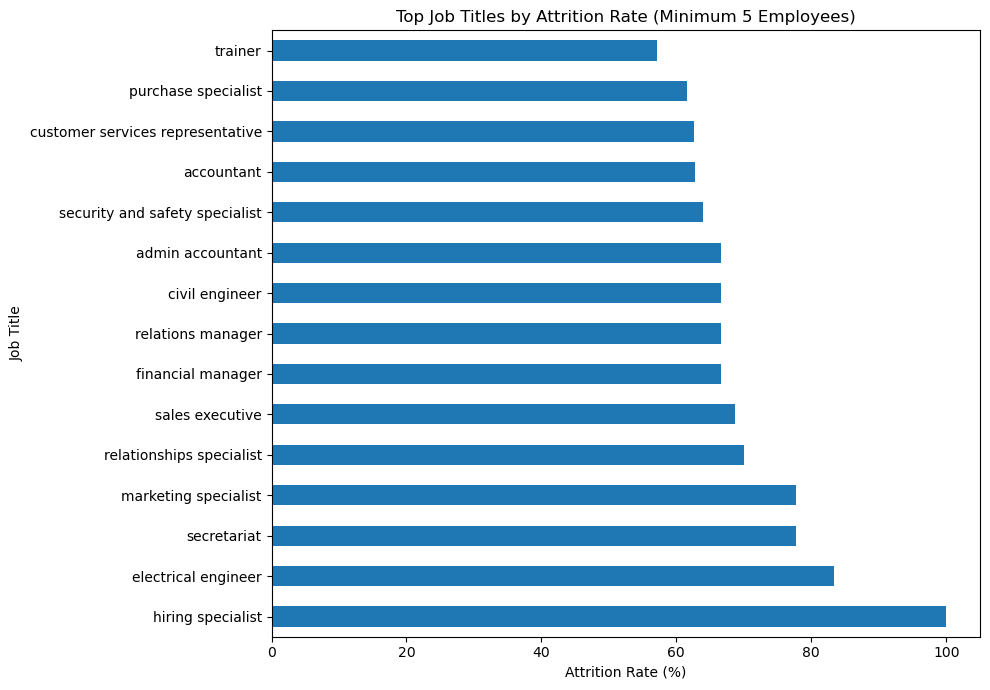

In [29]:
top_job_titles = job_title_filtered.head(15)

top_job_titles.plot(
    x="JobTitle",
    y="AttritionRate",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("Top Job Titles by Attrition Rate (Minimum 5 Employees)")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

In [30]:
salary_attrition = (
    df.groupby("MonthlySalary")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

salary_attrition["AttritionRate"] = (
    salary_attrition["mean"] * 100
)

salary_order = [
    "Less than 5000 SAR",
    "From 5000 to 10000 S.R",
    "From 11000 to 15000 S.R",
    "From 16000 to 20000 S.R",
    "From 21000 to 25000 S.R",
    "From 26000 to 30000 S.R",
    "S.R 31000 - and more"
]

salary_attrition["MonthlySalary"] = pd.Categorical(
    salary_attrition["MonthlySalary"],
    categories=salary_order,
    ordered=True
)

salary_attrition = salary_attrition.sort_values("MonthlySalary")

salary_attrition

,MonthlySalary,count,sum,mean,AttritionRate
5,Less than 5000 SAR,492,221,0.449187,44.918699
4,From 5000 to 10000 S.R,491,200,0.407332,40.733198
0,From 11000 to 15000 S.R,155,70,0.451613,45.161290
1,From 16000 to 20000 S.R,31,16,0.516129,51.612903
2,From 21000 to 25000 S.R,2,1,0.500000,50.000000
3,From 26000 to 30000 S.R,5,3,0.600000,60.000000
6,S.R 31000 - and more,15,4,0.266667,26.666667


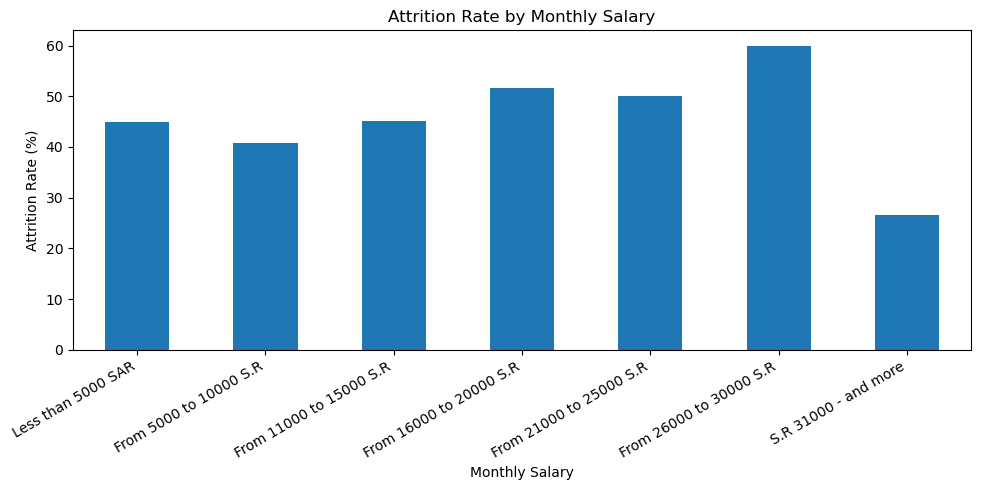

In [31]:
salary_attrition.plot(
    x="MonthlySalary",
    y="AttritionRate",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Attrition Rate by Monthly Salary")
plt.xlabel("Monthly Salary")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [32]:
allowance_attrition = (
    df.groupby("Allowances")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

allowance_attrition["AttritionRate"] = (
    allowance_attrition["mean"] * 100
)

allowance_attrition = allowance_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

allowance_attrition

,Allowances,count,sum,mean,AttritionRate
1,1,265,142,0.535849,53.584906
2,2,314,158,0.503185,50.318471
0,0,445,175,0.393258,39.325843
3,3,105,33,0.314286,31.428571
4,4,62,7,0.112903,11.290323


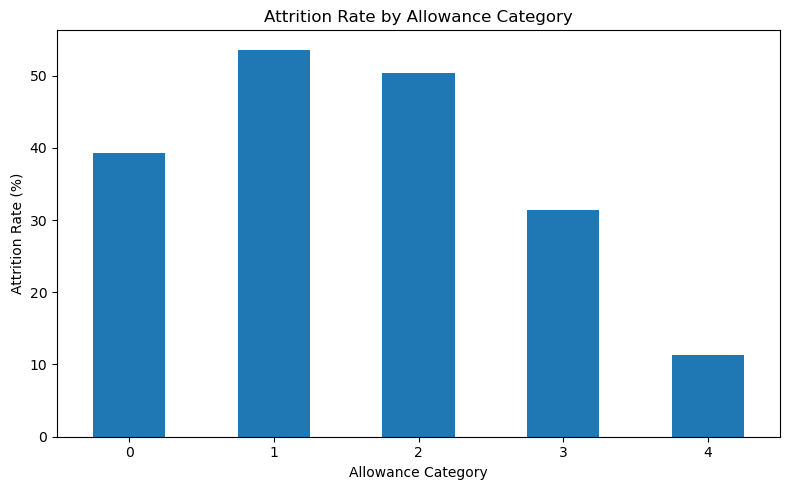

In [33]:
allowance_attrition = allowance_attrition.sort_values("Allowances")

allowance_attrition.plot(
    x="Allowances",
    y="AttritionRate",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Attrition Rate by Allowance Category")
plt.xlabel("Allowance Category")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
bonus_attrition = (
    df.groupby("Bonus")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

bonus_attrition["AttritionRate"] = (
    bonus_attrition["mean"] * 100
)

bonus_attrition = bonus_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

bonus_attrition

,Bonus,count,sum,mean,AttritionRate
0,No,698,316,0.452722,45.272206
1,Yes,493,199,0.403651,40.365112


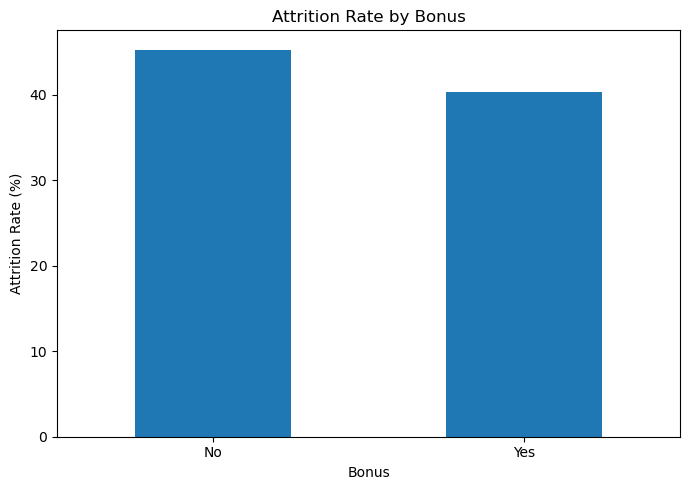

In [35]:
bonus_attrition.plot(
    x="Bonus",
    y="AttritionRate",
    kind="bar",
    figsize=(7, 5),
    legend=False
)

plt.title("Attrition Rate by Bonus")
plt.xlabel("Bonus")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
overtime_attrition = (
    df.groupby("OverTime")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

overtime_attrition["AttritionRate"] = (
    overtime_attrition["mean"] * 100
)

overtime_attrition = overtime_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

overtime_attrition

,OverTime,count,sum,mean,AttritionRate
1,Yes,511,224,0.438356,43.835616
0,No,680,291,0.427941,42.794118


In [37]:
overtime_payment_attrition = (
    df.groupby("Payment_Overtime")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

overtime_payment_attrition["AttritionRate"] = (
    overtime_payment_attrition["mean"] * 100
)

overtime_payment_attrition = overtime_payment_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

overtime_payment_attrition

,Payment_Overtime,count,sum,mean,AttritionRate
1,No,226,117,0.517699,51.769912
0,I don't have overtime,549,234,0.426230,42.622951
2,Yes,416,164,0.394231,39.423077


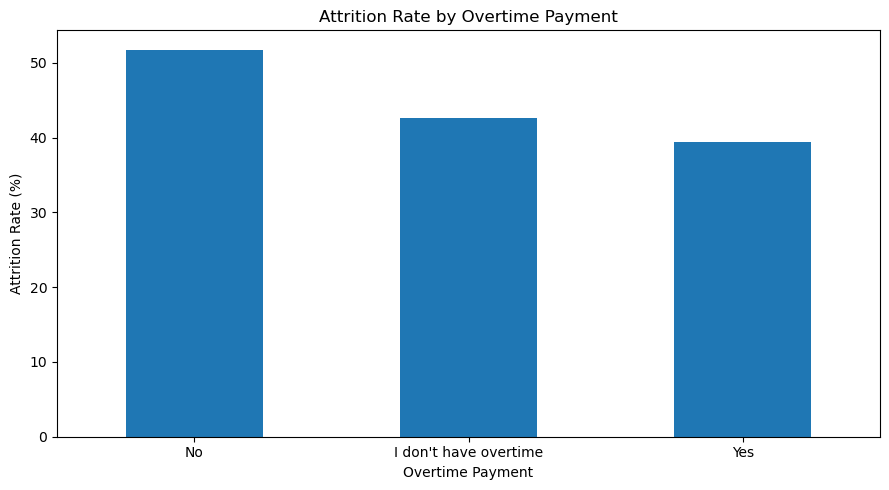

In [38]:
overtime_payment_attrition.plot(
    x="Payment_Overtime",
    y="AttritionRate",
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Attrition Rate by Overtime Payment")
plt.xlabel("Overtime Payment")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [39]:
rewards_attrition = (
    df.groupby("Rewards_Wages_Satisfaction")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

rewards_attrition["AttritionRate"] = (
    rewards_attrition["mean"] * 100
)

rewards_attrition = rewards_attrition.sort_values(
    "AttritionRate",
    ascending=False
)

rewards_attrition

,Rewards_Wages_Satisfaction,count,sum,mean,AttritionRate
0,No,617,334,0.541329,54.132901
1,Yes,574,181,0.315331,31.533101


In [40]:
job_satisfaction_attrition = (
    df.groupby("Job_Satisfaction")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_satisfaction_attrition["AttritionRate"] = (
    job_satisfaction_attrition["mean"] * 100
)

job_satisfaction_attrition

,Job_Satisfaction,count,sum,mean,AttritionRate
0,Not satisfied,293,171,0.583618,58.361775
1,Satisfied,646,279,0.431889,43.188854
2,Very satisfied,252,65,0.257937,25.793651


In [41]:
environment_satisfaction_attrition = (
    df.groupby("Environment_Satisfaction")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

environment_satisfaction_attrition["AttritionRate"] = (
    environment_satisfaction_attrition["mean"] * 100
)

environment_satisfaction_attrition

,Environment_Satisfaction,count,sum,mean,AttritionRate
0,High,307,106,0.345277,34.527687
1,Low,205,112,0.546341,54.634146
2,Medium,679,297,0.437408,43.740795


In [42]:
emotional_commitment_attrition = (
    df.groupby("Emotional_Commitment")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

emotional_commitment_attrition["AttritionRate"] = (
    emotional_commitment_attrition["mean"] * 100
)

emotional_commitment_attrition

,Emotional_Commitment,count,sum,mean,AttritionRate
0,High,468,135,0.288462,28.846154
1,Low,224,127,0.566964,56.696429
2,Medium,499,253,0.507014,50.701403


In [43]:
job_engagement_attrition = (
    df.groupby("Job_Engagement")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_engagement_attrition["AttritionRate"] = (
    job_engagement_attrition["mean"] * 100
)

job_engagement_attrition

,Job_Engagement,count,sum,mean,AttritionRate
0,Difficult,208,127,0.610577,61.057692
1,Easy,228,79,0.346491,34.649123
2,Medium,755,309,0.409272,40.927152


In [44]:
job_support_attrition = (
    df.groupby("Job_Support")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_support_attrition["AttritionRate"] = (
    job_support_attrition["mean"] * 100
)

job_support_attrition

,Job_Support,count,sum,mean,AttritionRate
0,High,346,95,0.274566,27.456647
1,Low,352,180,0.511364,51.136364
2,Medium,493,240,0.486815,48.681542


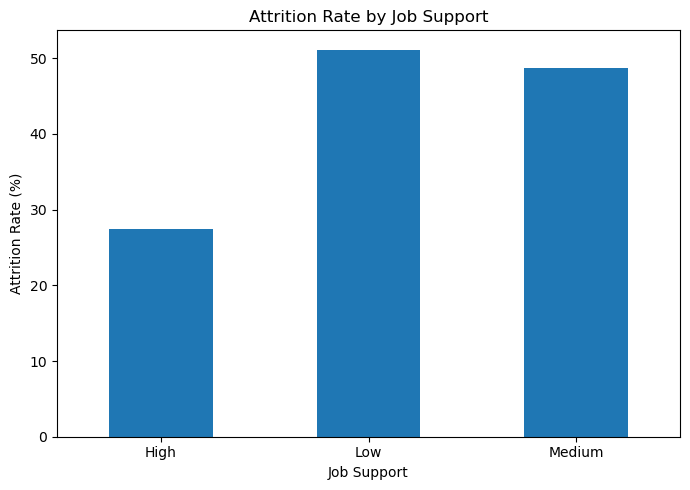

In [45]:
job_support_attrition.plot(
    x="Job_Support",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Job Support")
plt.xlabel("Job Support")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
recognition_attrition = (
    df.groupby("Recognition")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

recognition_attrition["AttritionRate"] = (
    recognition_attrition["mean"] * 100
)

recognition_attrition

,Recognition,count,sum,mean,AttritionRate
0,No,423,231,0.546099,54.609929
1,Yes,768,284,0.369792,36.979167


In [47]:
promotion_attrition = (
    df.groupby("Get__Deserved_Promotion")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

promotion_attrition["AttritionRate"] = (
    promotion_attrition["mean"] * 100
)

promotion_attrition

,Get__Deserved_Promotion,count,sum,mean,AttritionRate
0,No,695,370,0.532374,53.237410
1,Yes,496,145,0.292339,29.233871


In [48]:
training_attrition = (
    df.groupby("Training_programs__During_last_three_years")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

training_attrition["AttritionRate"] = (
    training_attrition["mean"] * 100
)

training_attrition

,Training_programs__During_last_three_years,count,sum,mean,AttritionRate
0,From 1 to 3 training programs,446,232,0.520179,52.017937
1,From 4 to 6 training programs,188,70,0.372340,37.234043
2,From 7 training programs to more,174,23,0.132184,13.218391
3,I did not receive any training,383,190,0.496084,49.608355


In [49]:
useful_training_attrition = (
    df.groupby("Useful_Training_Programs")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

useful_training_attrition["AttritionRate"] = (
    useful_training_attrition["mean"] * 100
)

useful_training_attrition

,Useful_Training_Programs,count,sum,mean,AttritionRate
0,No,434,229,0.527650,52.764977
1,Yes,757,286,0.377807,37.780713


In [50]:
worklife_attrition = (
    df.groupby("Work_Live_Balance")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

worklife_attrition["AttritionRate"] = (
    worklife_attrition["mean"] * 100
)

worklife_attrition

,Work_Live_Balance,count,sum,mean,AttritionRate
0,Difficult,222,133,0.599099,59.909910
1,Easy,246,85,0.345528,34.552846
2,Medium,723,297,0.410788,41.078838


In [3]:
job_stability_attrition = (
    df.groupby("Job_Stability")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_stability_attrition["AttritionRate"] = (
    job_stability_attrition["mean"] * 100
)

job_stability_attrition

,Job_Stability,count,sum,mean,AttritionRate
0,No,618,342,0.553398,55.339806
1,Yes,573,173,0.301920,30.191972


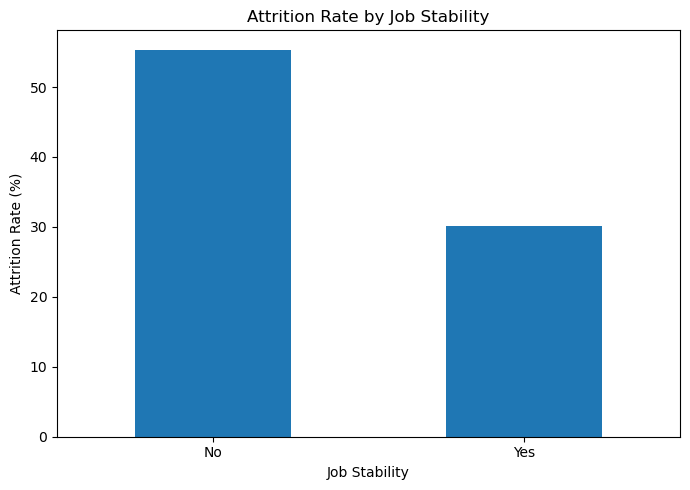

In [4]:
job_stability_attrition.plot(
    x="Job_Stability",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Job Stability")
plt.xlabel("Job Stability")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
job_opportunities_attrition = (
    df.groupby("Job_Opportunities")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

job_opportunities_attrition["AttritionRate"] = (
    job_opportunities_attrition["mean"] * 100
)

job_opportunities_attrition

,Job_Opportunities,count,sum,mean,AttritionRate
0,No,606,159,0.262376,26.237624
1,Yes,585,356,0.608547,60.854701


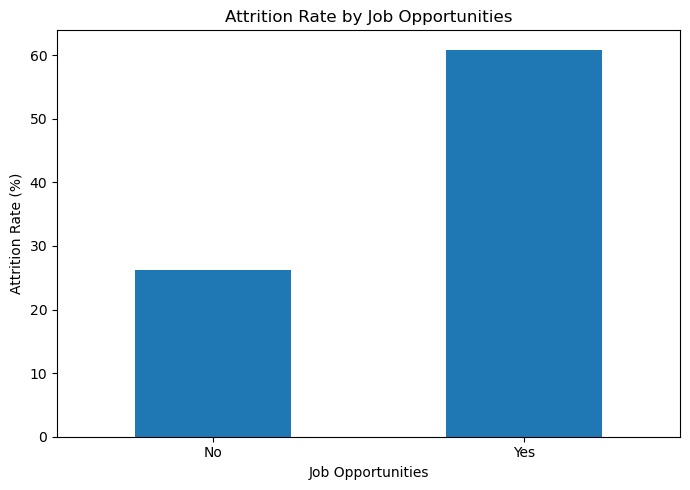

In [6]:
job_opportunities_attrition.plot(
    x="Job_Opportunities",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Job Opportunities")
plt.xlabel("Job Opportunities")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
health_issues_attrition = (
    df.groupby("Health_Issues")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

health_issues_attrition["AttritionRate"] = (
    health_issues_attrition["mean"] * 100
)

health_issues_attrition

,Health_Issues,count,sum,mean,AttritionRate
0,No,998,415,0.415832,41.583166
1,Yes,193,100,0.518135,51.813472


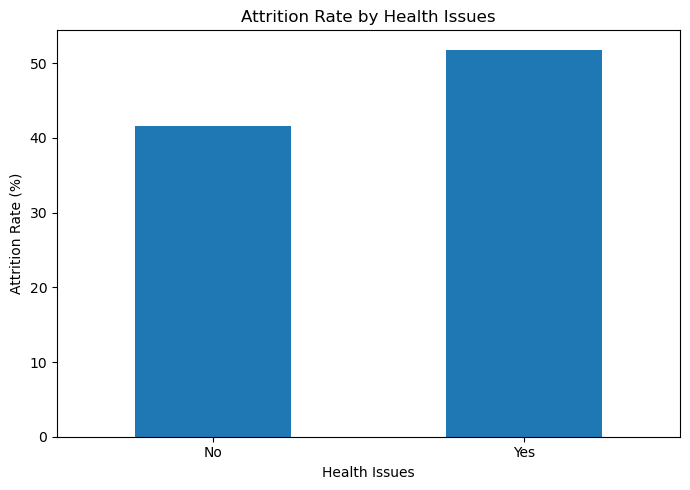

In [8]:
health_issues_attrition.plot(
    x="Health_Issues",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Health Issues")
plt.xlabel("Health Issues")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
distance_attrition = (
    df.groupby("Distance_to_work")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

distance_attrition["AttritionRate"] = (
    distance_attrition["mean"] * 100
)

distance_attrition

,Distance_to_work,count,sum,mean,AttritionRate
0,Close,381,160,0.419948,41.994751
1,Far,192,112,0.583333,58.333333
2,Medium,618,243,0.393204,39.320388


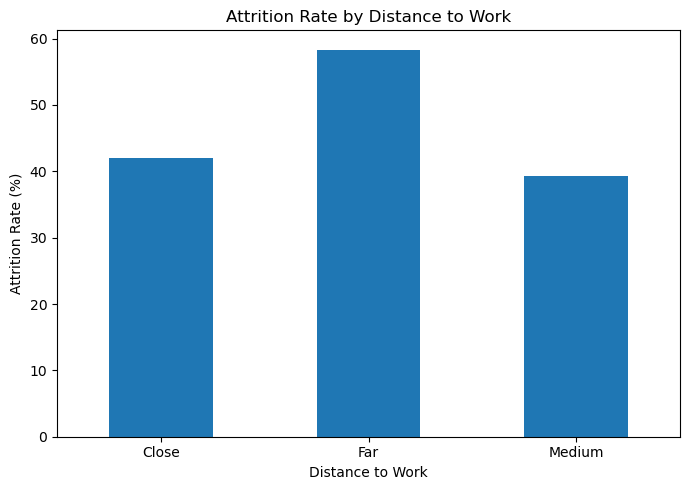

In [10]:
distance_attrition.plot(
    x="Distance_to_work",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Distance to Work")
plt.xlabel("Distance to Work")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [3]:
business_travel_attrition = (
    df.groupby("Business_Travel")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

business_travel_attrition["AttritionRate"] = (
    business_travel_attrition["mean"] * 100
)

business_travel_attrition

,Business_Travel,count,sum,mean,AttritionRate
0,I do not travel for work,860,371,0.431395,43.139535
1,Travel frequently,80,40,0.500000,50.000000
2,Travel rarely,251,104,0.414343,41.434263


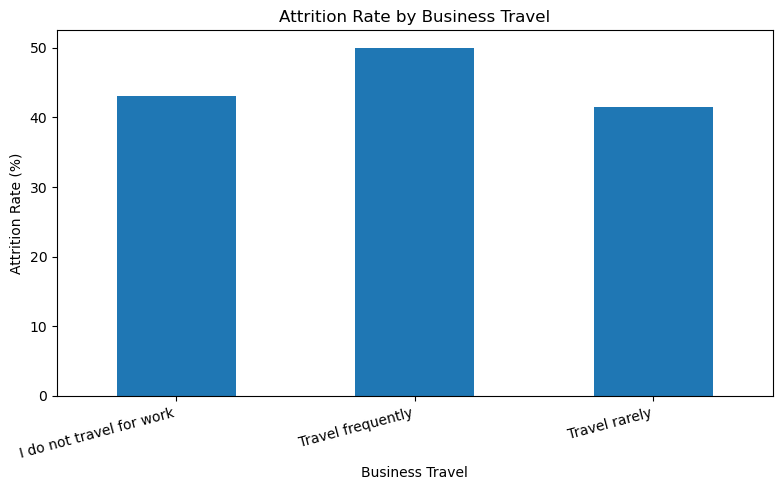

In [4]:
business_travel_attrition.plot(
    x="Business_Travel",
    y="AttritionRate",
    kind="bar",
    figsize=(8,5),
    legend=False
)

plt.title("Attrition Rate by Business Travel")
plt.xlabel("Business Travel")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [5]:
physical_stress_attrition = (
    df.groupby("Physical_Stress")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

physical_stress_attrition["AttritionRate"] = (
    physical_stress_attrition["mean"] * 100
)

physical_stress_attrition

,Physical_Stress,count,sum,mean,AttritionRate
0,No,361,148,0.409972,40.997230
1,Sometimes,450,164,0.364444,36.444444
2,Yes,380,203,0.534211,53.421053


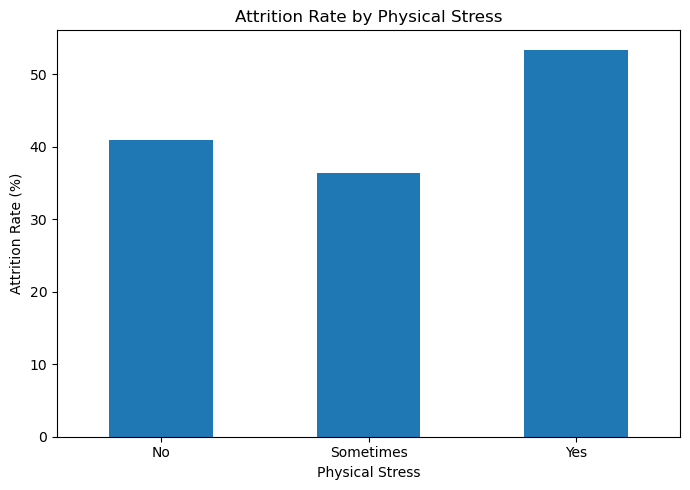

In [6]:
physical_stress_attrition.plot(
    x="Physical_Stress",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Physical Stress")
plt.xlabel("Physical Stress")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
psychological_exhaustion_attrition = (
    df.groupby("Psychological_Exhaustion")["AttritionFlag"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

psychological_exhaustion_attrition["AttritionRate"] = (
    psychological_exhaustion_attrition["mean"] * 100
)

psychological_exhaustion_attrition

,Psychological_Exhaustion,count,sum,mean,AttritionRate
0,No,357,114,0.319328,31.932773
1,Sometimes,430,194,0.451163,45.116279
2,Yes,404,207,0.512376,51.237624


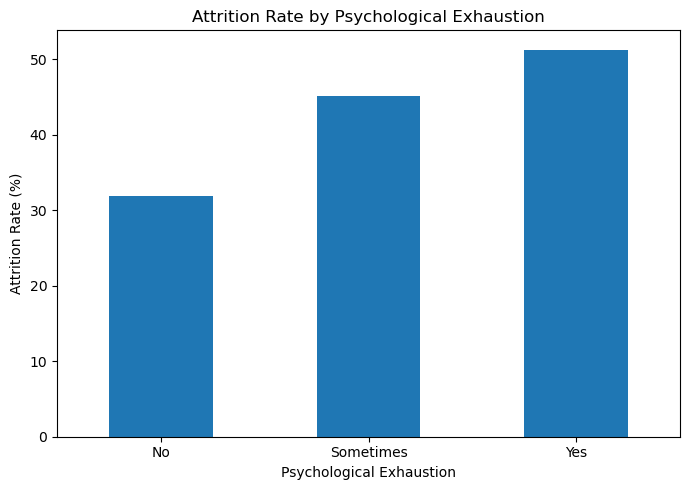

In [8]:
psychological_exhaustion_attrition["Psychological_Exhaustion"] = pd.Categorical(
    psychological_exhaustion_attrition["Psychological_Exhaustion"],
    categories=["No", "Sometimes", "Yes"],
    ordered=True
)

psychological_exhaustion_attrition = (
    psychological_exhaustion_attrition
    .sort_values("Psychological_Exhaustion")
)

psychological_exhaustion_attrition.plot(
    x="Psychological_Exhaustion",
    y="AttritionRate",
    kind="bar",
    figsize=(7,5),
    legend=False
)

plt.title("Attrition Rate by Psychological Exhaustion")
plt.xlabel("Psychological Exhaustion")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
factor_summary = pd.DataFrame({
    "Factor": [
        "Job Opportunities",
        "Job Satisfaction",
        "Emotional Commitment",
        "Job Engagement",
        "Work-Life Balance",
        "Job Stability",
        "Promotion Opportunity",
        "Job Support",
        "Rewards & Wages Satisfaction",
        "Environment Satisfaction",
        "Distance to Work",
        "Psychological Exhaustion",
        "Recognition",
        "Physical Stress",
        "Useful Training Programs",
        "Payment for Overtime",
        "Health Issues",
        "Business Travel",
        "Marital Status",
        "Bonus",
        "Overtime"
    ],
    
    "Difference": [
        60.854701 - 26.237624,
        58.361775 - 25.793651,
        56.696429 - 28.846154,
        61.057692 - 34.649123,
        59.909910 - 34.552846,
        55.339806 - 30.191972,
        53.237410 - 29.233871,
        51.136364 - 27.456647,
        54.132901 - 31.533101,
        54.634146 - 34.527687,
        58.333333 - 39.320388,
        51.237624 - 31.932773,
        54.609929 - 36.979167,
        53.421053 - 36.444444,
        52.764977 - 37.780713,
        51.769912 - 39.423077,
        51.813472 - 41.583166,
        50.000000 - 41.434263,
        48.000000 - 41.545190,
        45.272206 - 40.365112,
        43.835616 - 42.794118
    ]
})

factor_summary["Difference"] = factor_summary["Difference"].round(2)

factor_summary = factor_summary.sort_values(
    "Difference",
    ascending=False
).reset_index(drop=True)

factor_summary.insert(
    0,
    "Rank",
    range(1, len(factor_summary) + 1)
)

factor_summary

,Rank,Factor,Difference
0,1,Job Opportunities,34.62
1,2,Job Satisfaction,32.57
2,3,Emotional Commitment,27.85
3,4,Job Engagement,26.41
4,5,Work-Life Balance,25.36
5,6,Job Stability,25.15
6,7,Promotion Opportunity,24.00
7,8,Job Support,23.68
8,9,Rewards & Wages Satisfaction,22.60
9,10,Environment Satisfaction,20.11


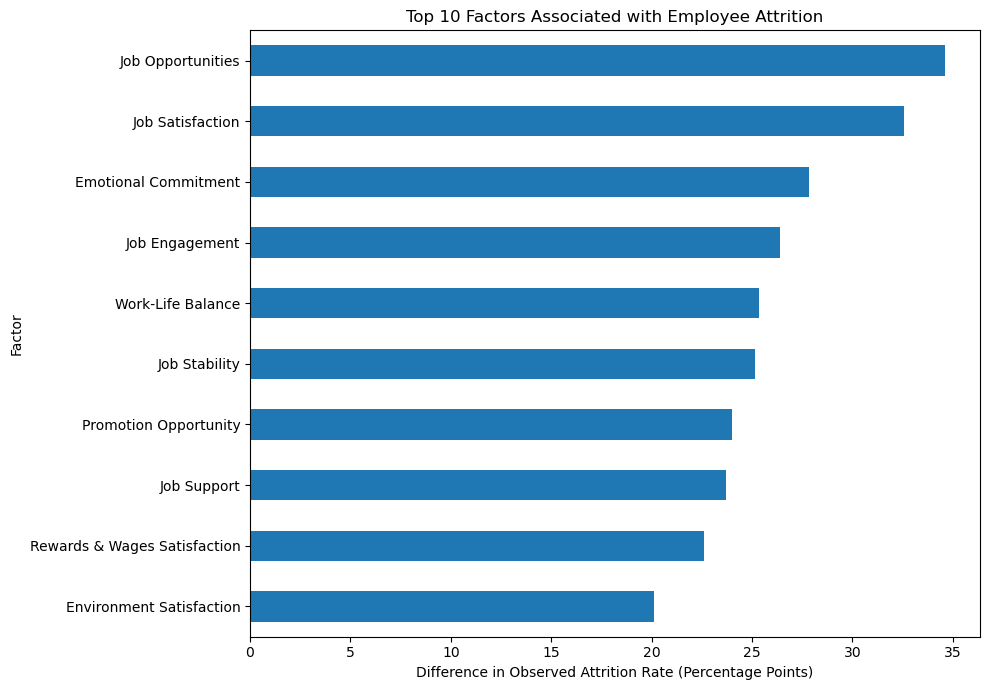

In [8]:
top_factors = factor_summary.head(10)

top_factors = top_factors.sort_values(
    "Difference",
    ascending=True
)

top_factors.plot(
    x="Factor",
    y="Difference",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("Top 10 Factors Associated with Employee Attrition")
plt.xlabel("Difference in Observed Attrition Rate (Percentage Points)")
plt.ylabel("Factor")
plt.tight_layout()
plt.show()

# 8. Final EDA Summary

This exploratory analysis examined 1,191 employee records from the Saudi Employee Attrition Dataset to identify patterns associated with employee attrition.

The analysis covered demographic characteristics, workforce experience, compensation, job satisfaction, employee engagement, workplace conditions, and wellbeing factors.

The overall observed attrition rate in the dataset is 43.24%.

In [9]:
# Final dataset overview

print("EDA SUMMARY")
print("-" * 40)

print(f"Total Employees/Respondents : {len(df):,}")
print(f"Attrition Count             : {df['AttritionFlag'].sum():,}")
print(f"Attrition Rate              : {df['AttritionFlag'].mean() * 100:.2f}%")
print(f"Number of Features          : {df.shape[1]:,}")

EDA SUMMARY
----------------------------------------
Total Employees/Respondents : 1,191
Attrition Count             : 515
Attrition Rate              : 43.24%
Number of Features          : 44


## 8.2 Key EDA Findings

The major findings from the exploratory analysis are:

### Demographic Findings
- Male employees showed a higher observed attrition rate than female employees.
- Employees aged 21–30 and 31–40 showed relatively higher attrition than the 41–50 group.
- Divorced employees had the highest observed attrition rate among marital-status groups, but the sample size was small.
- Attrition rates across Bachelor's, Master's, and Diploma/Secondary education groups were relatively similar.

### Workforce & Experience Findings
- Employees with 5–10 years of total experience had a relatively high observed attrition rate.
- Employees with less than 5 years at their last organization showed substantially higher observed attrition than employees with longer organizational tenure.
- Attrition varied considerably across sectors and job titles.

### Compensation Findings
- Allowance categories showed a strong inverse association with observed attrition.
- Employees dissatisfied with rewards and wages had substantially higher observed attrition.
- Employees without bonuses showed slightly higher attrition.
- Overtime itself showed only a weak difference in observed attrition.
- Employees reporting unpaid overtime had higher observed attrition than employees receiving overtime payment.

### Job Satisfaction & Engagement Findings
- Job satisfaction was one of the strongest factors associated with attrition.
- Employees reporting low emotional commitment showed higher observed attrition.
- Difficult job engagement was associated with substantially higher attrition.
- Lower job support and lack of recognition were associated with higher attrition.
- Employees reporting no deserved promotion opportunity had substantially higher observed attrition.
- Training patterns also showed meaningful differences in observed attrition.

### Workplace & Wellbeing Findings
- Lack of job stability was associated with higher observed attrition.
- Job opportunities showed the largest difference in observed attrition among the analyzed factors.
- Employees reporting health issues showed moderately higher attrition.
- Employees reporting a far distance to work had higher observed attrition.
- Psychological exhaustion showed a clear positive association with attrition.
- Employees reporting physical stress also showed higher observed attrition.

## 8.3 Top 10 Factors Associated with Attrition

The following factors showed the largest differences between their highest and lowest observed attrition rates.

| Rank | Factor | Difference in Observed Attrition Rate |
|---:|---|---:|
| 1 | Job Opportunities | 34.62 pp |
| 2 | Job Satisfaction | 32.57 pp |
| 3 | Emotional Commitment | 27.85 pp |
| 4 | Job Engagement | 26.41 pp |
| 5 | Work-Life Balance | 25.36 pp |
| 6 | Job Stability | 25.15 pp |
| 7 | Promotion Opportunity | 24.00 pp |
| 8 | Job Support | 23.68 pp |
| 9 | Rewards & Wages Satisfaction | 22.60 pp |
| 10 | Environment Satisfaction | 20.11 pp |

These rankings are descriptive and represent differences in observed attrition rates across categories. They should not be interpreted as causal effects or statistical feature importance.

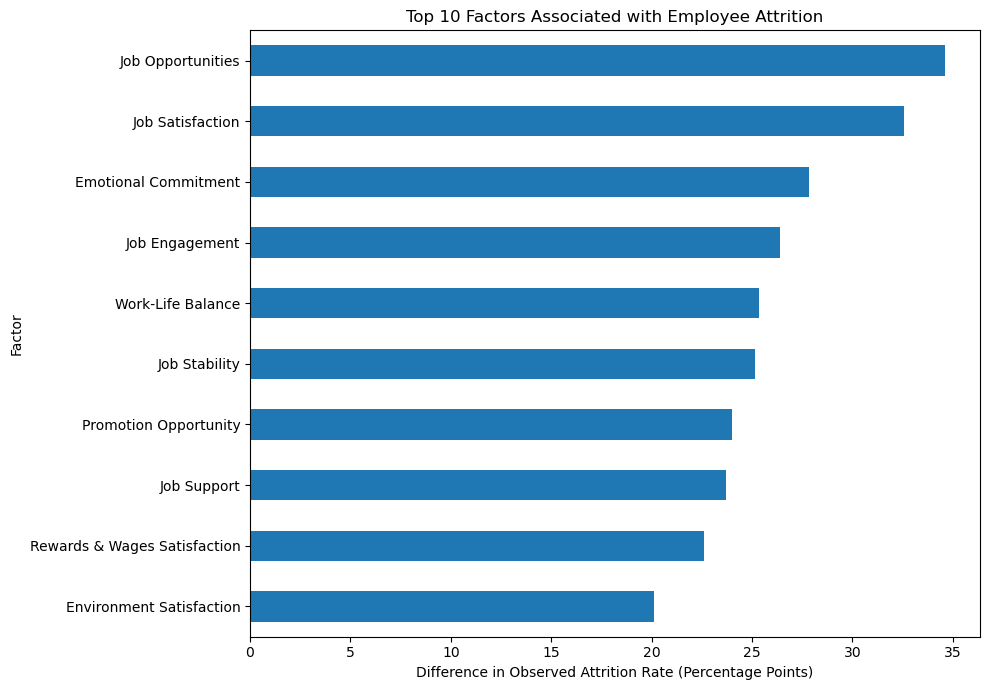

In [10]:
top_factors = factor_summary.head(10).copy()

top_factors = top_factors.sort_values(
    "Difference",
    ascending=True
)

top_factors.plot(
    x="Factor",
    y="Difference",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("Top 10 Factors Associated with Employee Attrition")
plt.xlabel(
    "Difference in Observed Attrition Rate (Percentage Points)"
)
plt.ylabel("Factor")

plt.tight_layout()
plt.show()

## 8.5 HR Business Recommendations

Based on the observed patterns in the data, the following HR actions could be considered:

### 1. Strengthen Career Growth and Internal Mobility
Develop clearer career paths, improve promotion transparency, and provide internal mobility opportunities.

### 2. Improve Job Satisfaction and Employee Engagement
Conduct regular employee feedback surveys and identify teams with lower satisfaction and engagement levels.

### 3. Improve Work-Life Balance and Employee Support
Review workload, working-hour patterns, managerial support, and flexible-work options where operationally feasible.

### 4. Strengthen Recognition and Rewards
Review reward structures and introduce consistent employee recognition practices.

### 5. Address Employee Wellbeing
Monitor psychological exhaustion, physical stress, and health-related concerns and provide appropriate employee support.

### 6. Address Commuting and Travel Challenges
Identify employees facing long commuting distances or frequent business travel and evaluate appropriate workplace flexibility or support.

### 7. Establish Proactive Attrition Monitoring
Use HR dashboards to continuously monitor attrition patterns across departments, sectors, job roles, satisfaction levels, compensation, and employee wellbeing.

## 8.6 Analysis Limitations

The following limitations should be considered when interpreting the results:

1. The analysis is based on survey data and represents observed responses from the dataset.

2. The analysis identifies associations between employee characteristics and attrition, but does not establish causation.

3. Some categories have relatively small sample sizes. Therefore, very high or very low attrition rates in those groups should be interpreted cautiously.

4. The attrition target should be interpreted according to the dataset documentation. It should not automatically be treated as a measured historical company turnover rate.

5. The factor ranking is based on the difference between the highest and lowest observed attrition rates. It is a descriptive EDA ranking, not a statistical feature-importance ranking.

6. Further statistical analysis or predictive modeling would be required to determine which variables independently contribute to attrition prediction.

## 8.7 Conclusion

The exploratory analysis shows substantial variation in observed employee attrition across career opportunities, job satisfaction, engagement, work-life balance, job stability, promotion opportunities, employee support, compensation satisfaction, and workplace wellbeing.

The strongest observed differences were associated with Job Opportunities, Job Satisfaction, Emotional Commitment, Job Engagement, and Work-Life Balance.

These findings provide a foundation for developing an HR analytics dashboard that enables management to monitor workforce patterns and identify areas requiring attention.

The next stage of the project will move the cleaned dataset into SQL Server for structured data storage, data-quality validation, KPI development, and business-oriented SQL analysis before building the final Power BI dashboard.